In [2]:
import numpy as np
import pandas as pd


In [3]:
ocr_data = pd.read_parquet("../data/interim/ocr.parquet")

ocr_data.head(3)

,path,label,split,text,mean_confidence,nb_words,tesseract_version,tesseract_lang,tesseract_config
0,train/2079129860.jpg,Email,train,"Horn, Bonnie T.\nFrom: Waish, Michael A. (Madd...",91.911111,45,5.5.3,eng,--oem 1 --psm 3
1,train/2085119305a.jpg,Email,train,"Chang, Yen\nFrom: Chang, Yen\nSent: Monday, Ma...",88.418605,43,5.5.3,eng,--oem 1 --psm 3
2,train/92206285.jpg,ADVE,train,SURGEON GENERAL'S WARNING: Quitting Smoking\nN...,91.076923,13,5.5.3,eng,--oem 1 --psm 3


In [4]:
ocr_data.shape

(2737, 9)

In [5]:
ocr_data.columns

Index(['path', 'label', 'split', 'text', 'mean_confidence', 'nb_words',
       'tesseract_version', 'tesseract_lang', 'tesseract_config'],
      dtype='str')

In [6]:
ocr_data['text'].isna().sum()

np.int64(0)

In [13]:
ocr_data_order_on_confidence = ocr_data.dropna(subset=["mean_confidence"]).sort_values("mean_confidence")

In [8]:
less_confidence = ocr_data.dropna(subset = ["mean_confidence"]).nsmallest(30, "mean_confidence")

less_confidence[["path", "label", "mean_confidence", "nb_words"]]

,path,label,mean_confidence,nb_words
723,train/1003188772.jpg,Note,6.000000,2
1810,train/2072237168.jpg,Note,8.000000,1
2686,train/2063603124.jpg,Note,8.000000,5
538,train/2021528870.jpg,Note,9.000000,1
2494,train/92221516_1518.jpg,ADVE,9.000000,1
1606,train/2505334571.jpg,Note,12.000000,8
1193,train/2048858141.jpg,Note,13.750000,4
2074,train/60019614.jpg,Note,14.750000,48
2140,train/2025319413.jpg,Note,19.382353,34
1949,train/2083306564.jpg,ADVE,19.444444,9


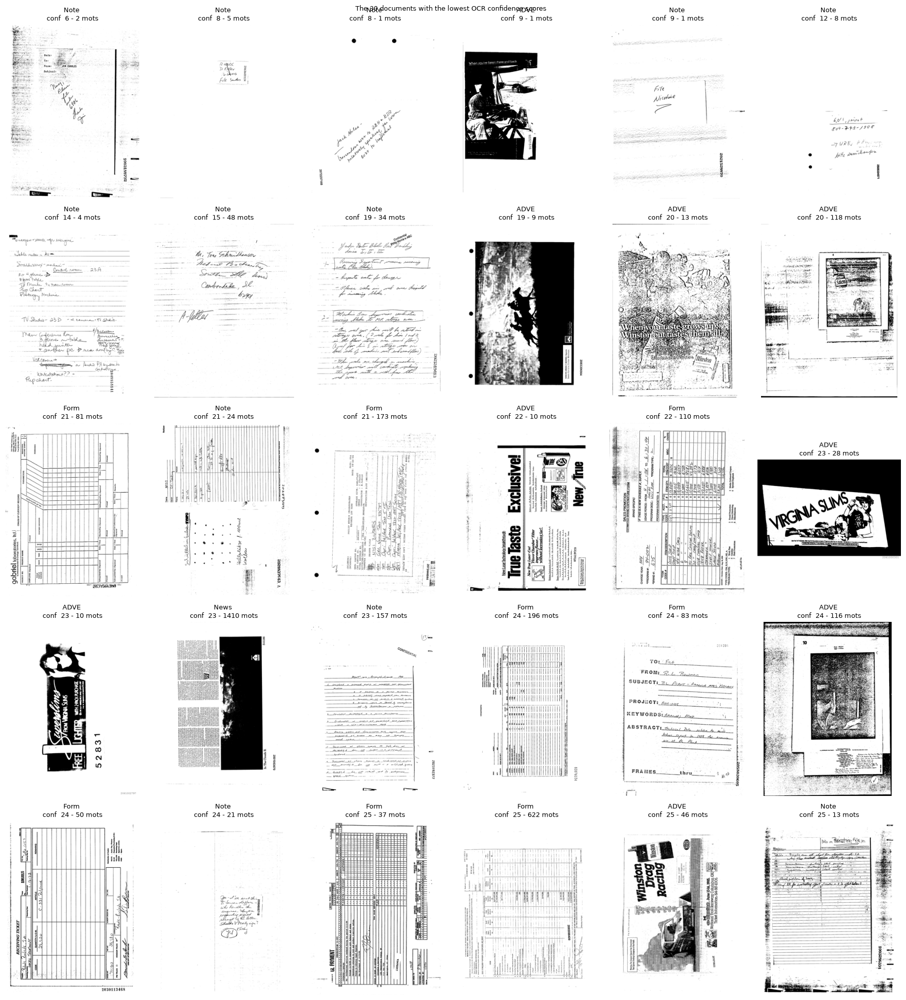

In [14]:
import math
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

_ROOT_PATH = Path.cwd().parent
_IMAGES_DIR = "data/raw"
_N_COLS = 6

def show_grid(df, root = _ROOT_PATH/_IMAGES_DIR, n_cols = _N_COLS) :
    n_rows = math.ceil(len(df) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize = (3* n_cols, 4* n_rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, (_, r) in zip(axes, df.iterrows()):
        with Image.open(_ROOT_PATH/_IMAGES_DIR / r["path"]) as img :
            img.thumbnail((400, 400))
            ax.imshow(img, cmap="gray")
            
        ax.set_title(f"{r['label']} \nconf {r['mean_confidence'] : .0f} - {int(r['nb_words'])} mots", fontsize = 9)
        ax.axis("off")
        
    for ax in axes[len(df):]:
        ax.axis("off")
        

    fig.suptitle("The 30 documents with the lowest OCR confidence scores", fontsize = 9)
    plt.tight_layout()
    plt.show()


show_grid(ocr_data_order_on_confidence.iloc[0:30])

*Out of 30, 13 images were flipped*

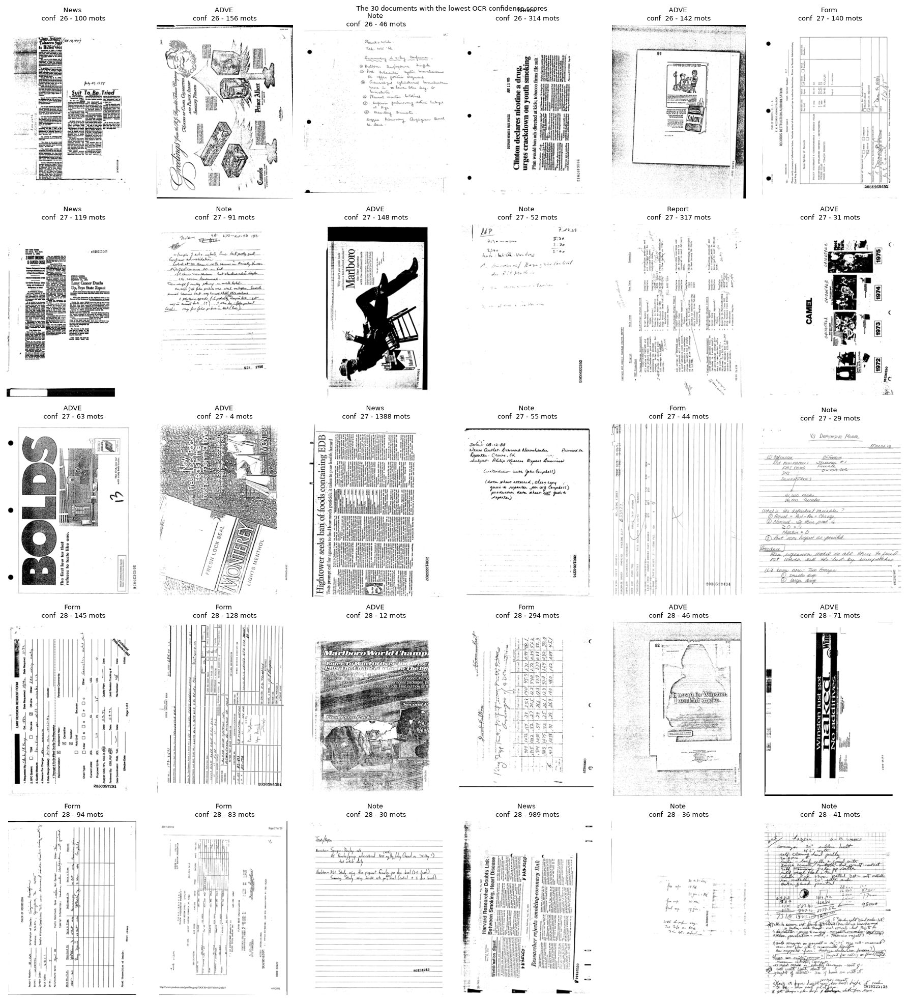

In [15]:
show_grid(ocr_data_order_on_confidence.iloc[30:60])

*out of 30, 17 images were flipped*

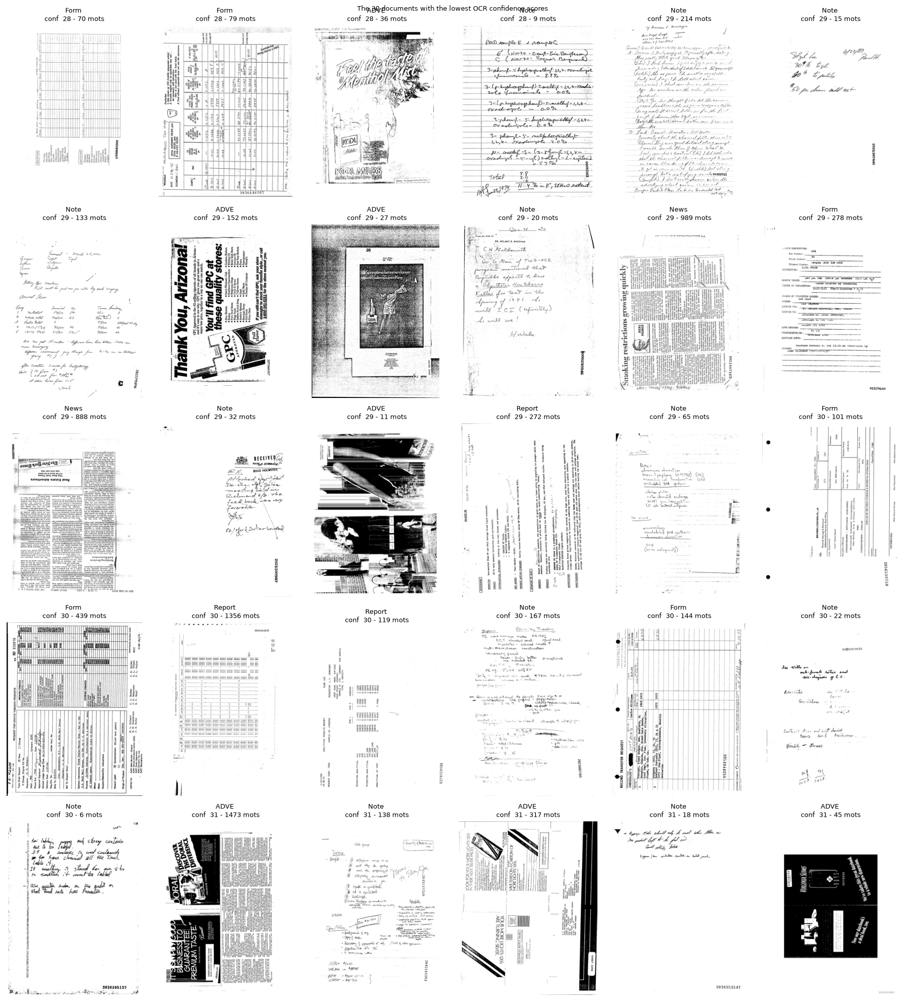

In [16]:
show_grid(ocr_data_order_on_confidence.iloc[60:90])

*out of 30, 12 images were flipped*

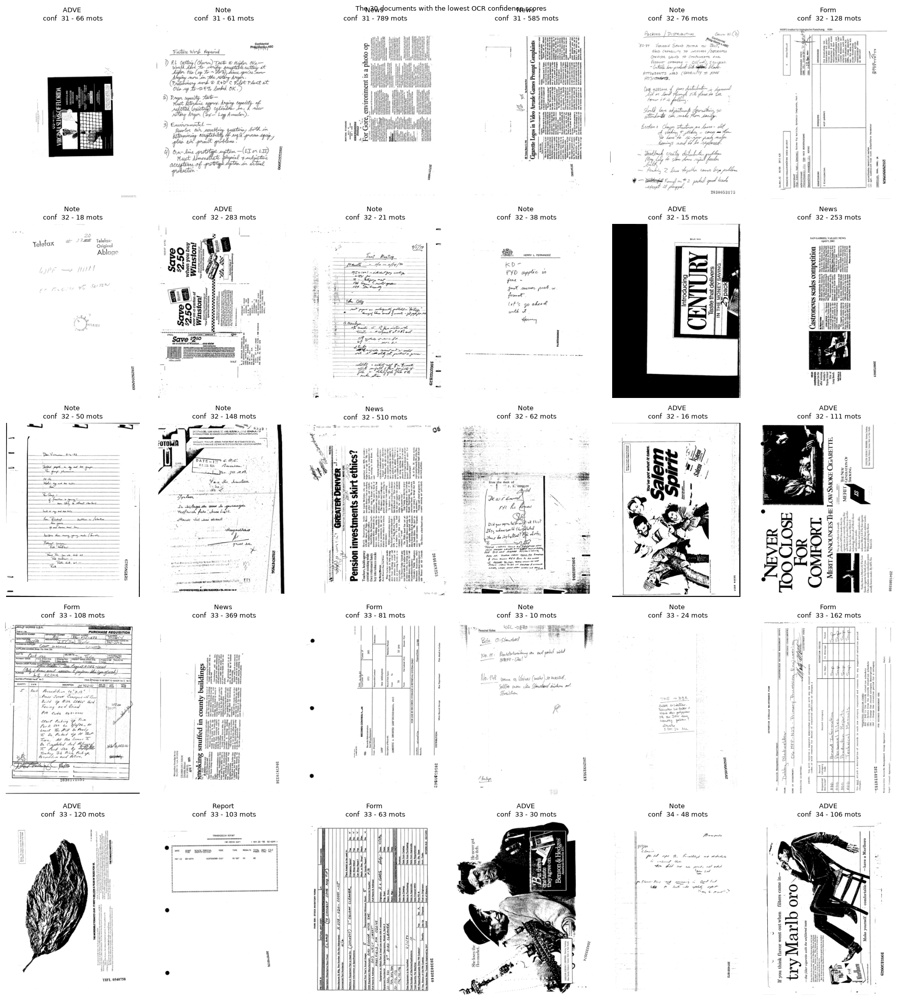

In [17]:
show_grid(ocr_data_order_on_confidence.iloc[90:120])

*out of 30, 15 images were flipped*

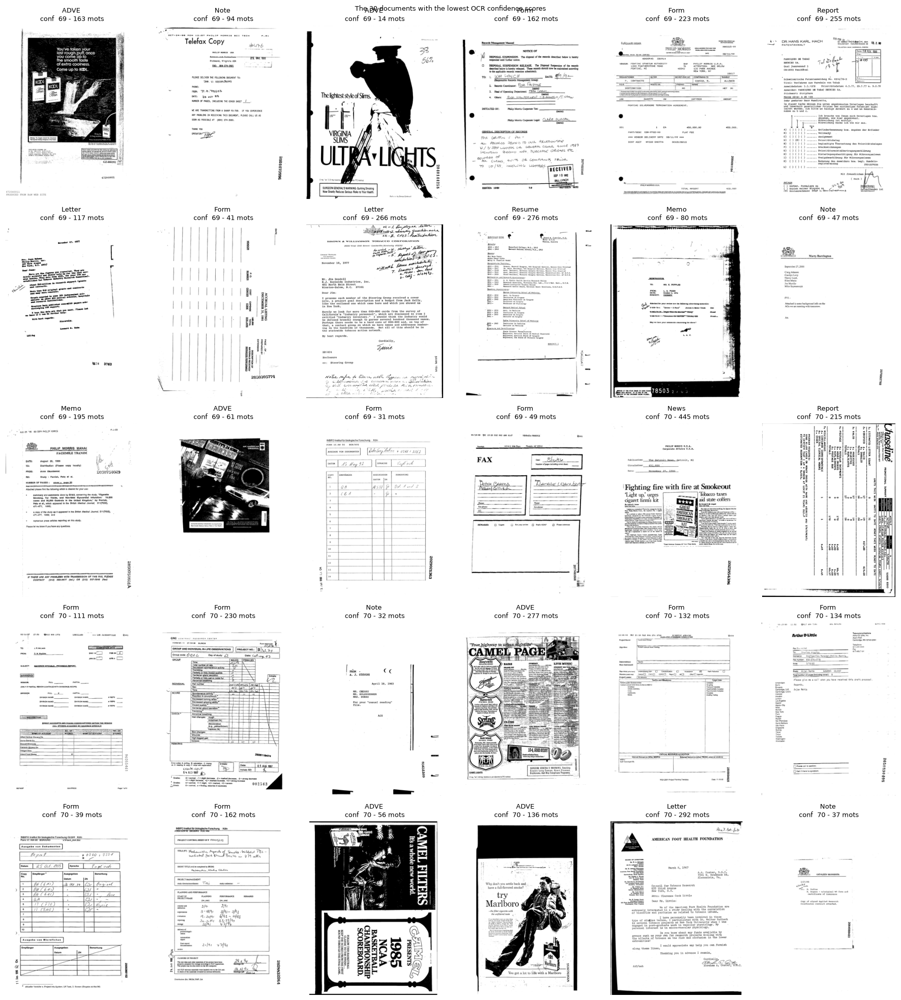

In [18]:
show_grid(ocr_data_order_on_confidence.iloc[500:530])

*out of 30, 3 images were flipped*

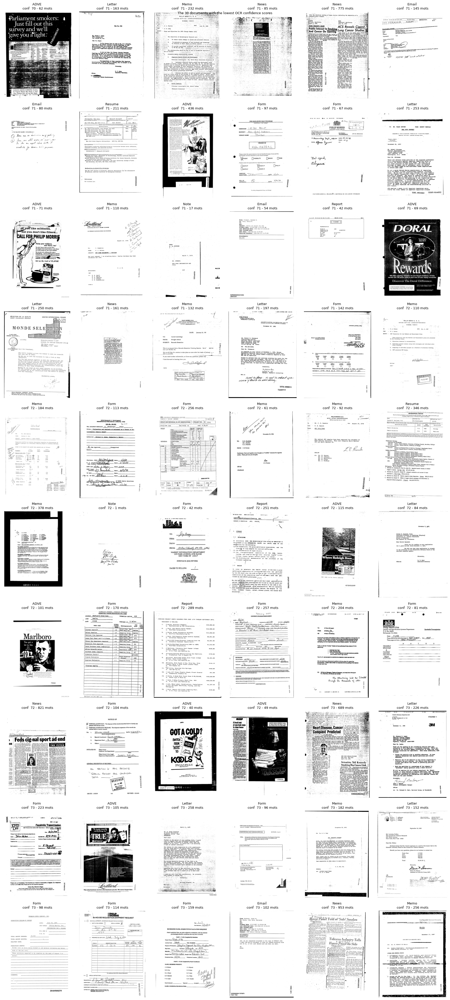

In [19]:
show_grid(ocr_data_order_on_confidence.iloc[530:590])

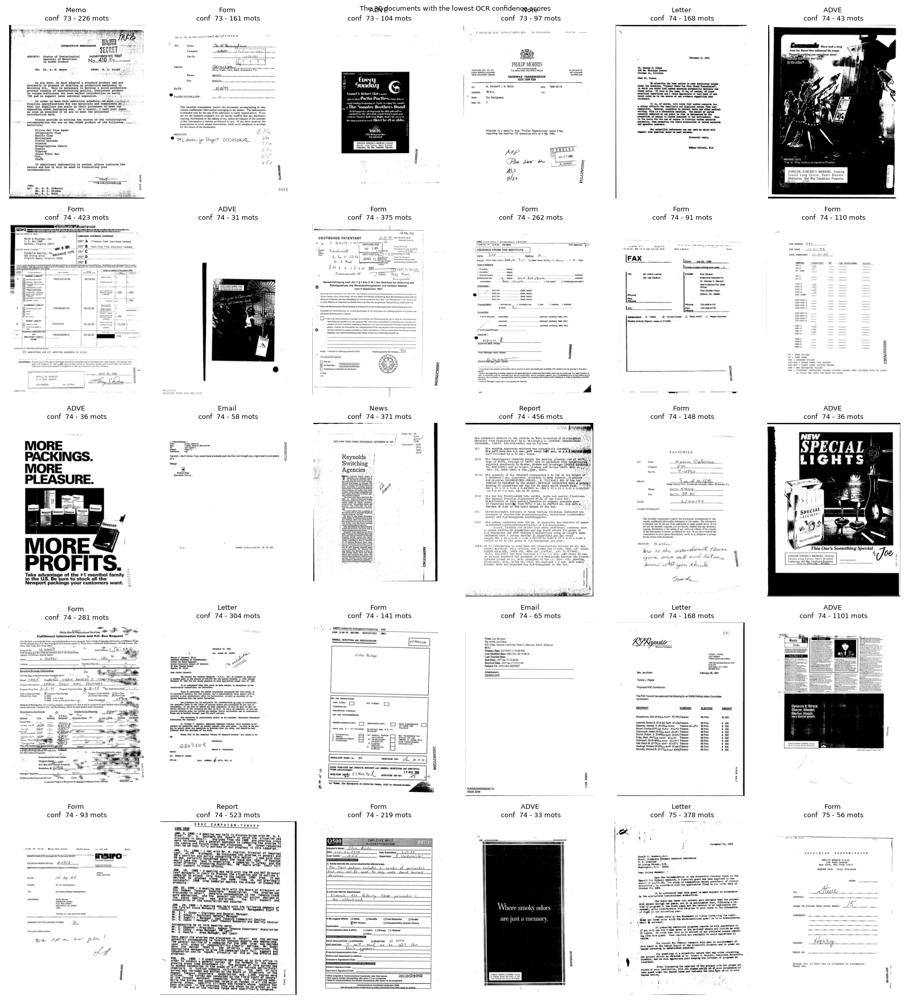

In [41]:
show_grid(ocr_data_order_on_confidence.iloc[600:630])

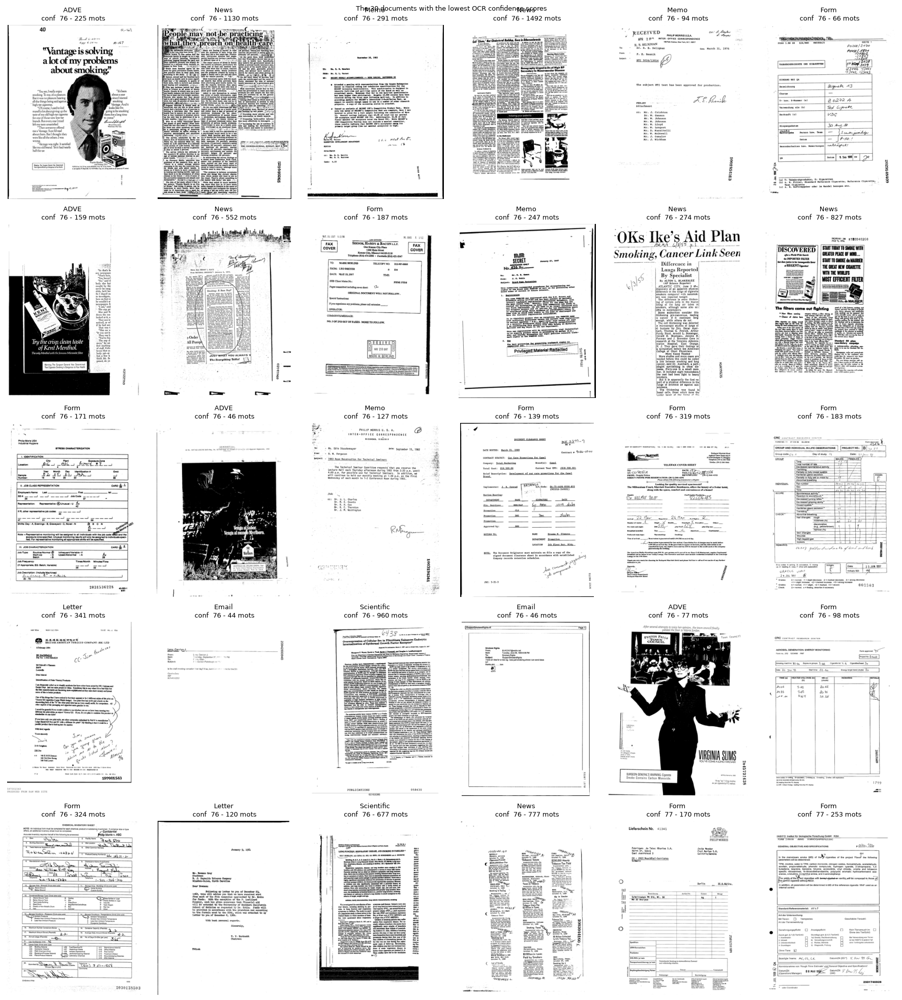

In [24]:
show_grid(ocr_data_order_on_confidence.iloc[660:690])

*Starting at confidence level 76, there really aren't many images taken.*

In [25]:
ocr_data[ocr_data["nb_words"] == 0]

,path,label,split,text,mean_confidence,nb_words,tesseract_version,tesseract_lang,tesseract_config
1620,train/501947737_501947738.jpg,Note,train,,NaN,0,5.5.3,eng,--oem 1 --psm 3
1918,train/1000261527.jpg,Note,val,,NaN,0,5.5.3,eng,--oem 1 --psm 3


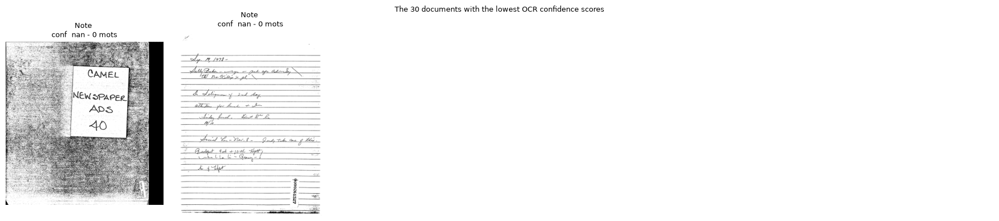

In [26]:
ocr_data_0_word = ocr_data[ocr_data["nb_words"] == 0]
show_grid(ocr_data_0_word)

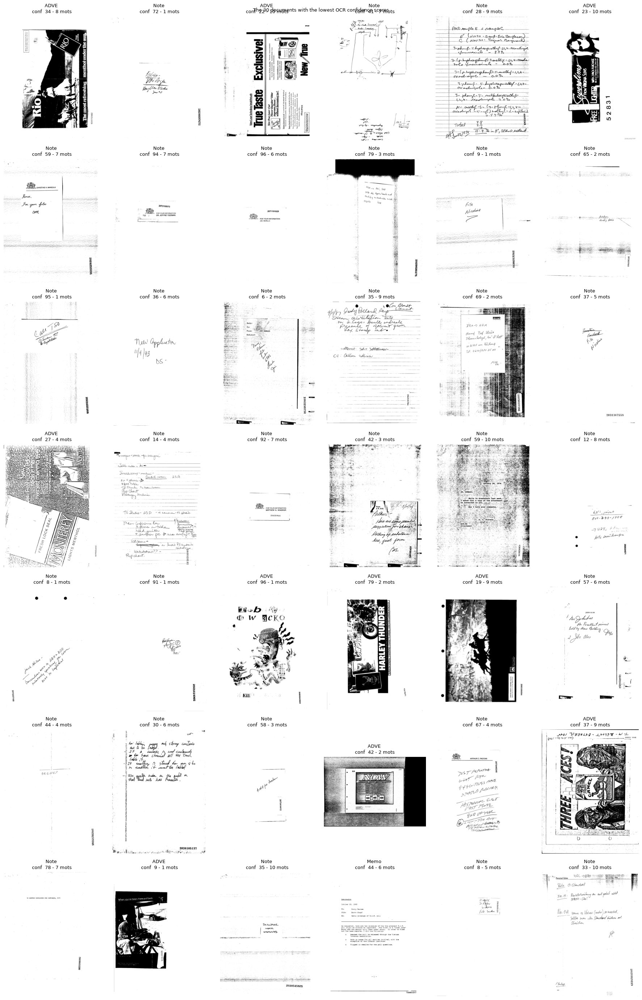

In [29]:
ocr_data_min_words = ocr_data[(ocr_data["nb_words"]  <= 10) & (ocr_data["nb_words"]  > 0)]
show_grid(ocr_data_min_words)

In [30]:
ocr_data_min_words.shape

(42, 9)

In [32]:
ocr_data_min_words["label"].value_counts()

label
Note    31
ADVE    10
Memo     1
Name: count, dtype: int64

/var/folders/zb/5qjkz41s5tg0qgdypxq_tnr80000gn/T/ipykernel_5118/2681417658.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})
/var/folders/zb/5qjkz41s5tg0qgdypxq_tnr80000gn/T/ipykernel_5118/2681417658.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})


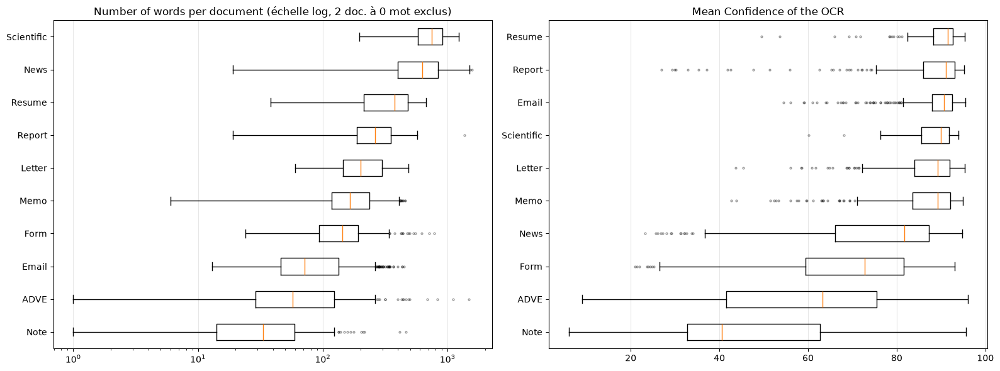

In [40]:
data = ocr_data.dropna(subset = ["text"])

def boxplot_per_class(ax, data, column, title, log=False):
    if log:
        n_zero = (data[column] <= 0).sum()
        data = data[data[column] > 0]   

    order = data.groupby("label")[column].median().sort_values().index
    values = [data.loc[data["label"] == c, column].dropna() for c in order]

    ax.boxplot(values, vert=False, showfliers=True, flierprops={"markersize": 2, "alpha": 0.4})
    ax.set_yticks(range(1, len(order) + 1), order)
    ax.grid(axis="x", alpha=0.3)

    if log:
        ax.set_xscale("log")
        title += f" (échelle log, {n_zero} doc. à 0 mot exclus)"
    ax.set_title(title)
    
fig, axes = plt.subplots(1, 2, figsize = (16, 6))
boxplot_per_class(axes[0], data, "nb_words", "Number of words per document", log = True)
boxplot_per_class(axes[1], data, "mean_confidence", "Mean Confidence of the OCR")
plt.tight_layout()
plt.show()

In [37]:
data = ocr_data.dropna(subset=["text"]).copy()
data["doc_id"] = data["path"].map(lambda p: Path(p).stem)    


data["id_exact"] = data.apply(lambda r: r["doc_id"] in r["text"], axis=1)


data["id_digits"] = data.apply(
    lambda r: r["doc_id"] in "".join(ch for ch in r["text"] if ch.isdigit()), axis=1
)

print(f"Id found(exact)     : {data['id_exact'].mean():.1%}")
print(f"Id found(tolérant)  : {data['id_digits'].mean():.1%}")

Id found(exact)     : 10.0%
Id found(tolérant)  : 10.3%


In [38]:
(data.groupby("label")[["id_exact", "id_digits"]].mean() * 100).round(1).sort_values("id_digits")

,id_exact,id_digits
label,,
Letter,0.0,0.0
Resume,0.0,0.0
Memo,0.4,0.4
Scientific,1.1,1.1
Report,2.4,2.4
News,8.6,9.7
Form,11.2,11.9
Note,12.7,12.7
ADVE,13.2,14.2


In [39]:
for _, r in data[data["id_exact"]].sample(5, random_state=0).iterrows():
    lignes = [l for l in r["text"].splitlines() if r["doc_id"] in l]
    print(f"{r['label']:<11} {r['doc_id']}  →  {lignes}")

Email       2077377563  →  ['2077377563']
News        2047870236  →  ['2047870236']
Scientific  2501387695  →  ['2501387695']
Email       2073528906  →  ['2073528906']
Email       2078307912  →  ['2078307912']


In [42]:
train = ocr_data[(ocr_data["split"] == "train")].dropna(subset=["mean_confidence"])
ratio = 600 / 2737    

quantile_threshold = train["mean_confidence"].quantile(ratio)

rang = round(ratio * len(train))      
threshold_rank = train["mean_confidence"].sort_values().iloc[rang - 1]

print(f"Quantile {ratio:.1%} of train : {quantile_threshold:.2f}")
print(f"Rank {rang} of train            : {threshold_rank:.2f}")

Quantile 21.9% of train : 73.94
Rank 420 of train            : 73.86


## OCR Analysis — Conclusions

### 1. OCR run
- All **2,737 documents** were processed, with **0 errors** and **0 missing documents** in the consolidated Parquet file (`data/interim/ocr.parquet`).
- Measured time: about **0.9 s per document**.
- The run was interrupted and restarted: the 1,504 documents already cached were skipped without recomputation. **Cache-based resumption works** (idempotence verified under real conditions).

### 2. Rotated pages
- Method: documents sorted by ascending mean confidence, then inspected visually in batches of 30.
  - up to rank ~450-500: **10 to 17 rotated pages per batch of 30**;
  - up to rank ~600: 1 to 3 per batch;
  - beyond: almost none (at most 1).
- Estimate: **about 150 to 200 rotated pages, i.e. 6 to 7% of the dataset**. The problem is too frequent to be ignored.
- Rotated pages are **concentrated in the ~600 lowest-confidence documents**: mean confidence is a good detector.

### 3. Empty or nearly empty documents
- **2 documents** have no words at all (both Note).
- **42 documents** have 10 words or fewer: **31 Note**, 10 ADVE and 1 Memo.
- About **19% of Notes** therefore have almost no usable text. For these documents, only the **image** can decide: a concrete argument for fusion.

### 4. Indicators by class
- **Rich, reliable text** (median confidence around 88-92): Resume, Report, Email, Scientific, Letter, Memo.
- **Noisy or sparse text**: News (median ~82), Form (~73), ADVE (~63) and above all **Note (~40)**. These are also the classes affected by handwriting, complex layouts and rotated pages.
- Word count: Scientific and News produce the most text (several hundred words), Note and ADVE the least (a few dozen).
- **Takeaway**: the text modality will be strong for some classes and weak for others. The two modalities should therefore be complementary.

### 5. Bates numbers (document ID in the text)
| Class | Exact ID found (%) | ID digits found (%) |
|---|---|---|
| Email | 29.6 | 30.1 |
| ADVE | 13.2 | 14.2 |
| Note | 12.7 | 12.7 |
| Form | 11.2 | 11.9 |
| News | 8.6 | 9.7 |
| Report | 2.4 | 2.4 |
| Scientific | 1.1 | 1.1 |
| Memo | 0.4 | 0.4 |
| Letter | 0.0 | 0.0 |
| Resume | 0.0 | 0.0 |

- The presence of the number depends on the **class** (30% of emails, never in Letters or Resumes). It is not related to the content but to how the pages were stamped and scanned: an **acquisition bias**, in the same family as the fax bias.
- Risk: the model could learn "a long number in the text means Email".

### 6. Decisions
- **Rotated page correction**:
  - confidence threshold set at **74**, determined on the **training set only** (21.9% quantile = 73.94; rank 420 = 73.86), equivalent to the ~600 lowest-confidence documents;
  - if the confidence at 0° is **below the threshold** (or there are no words), OCR is rerun at **90°, 180° and 270°**, and the orientation with the **highest confidence** is kept;
  - it is a **fixed threshold**, not a ranking: the rule applies document by document, so it works the same way in training and in production (Phase 3);
  - estimated cost: about **27 minutes** (3 orientations × ~600 documents), instead of more than 2 hours for the whole dataset;
  - the **selected angle** is recorded: it can also be used to straighten the image for the image encoder.
- **Cache update**:
  - the threshold and angle are added to the settings stored in each JSON file;
  - a JSON file is up to date if it contains the current settings. Otherwise, above the threshold, only `rotation = 0` is added; below it, the 3 other orientations are computed, reusing the 0° result already stored;
  - confidence alone cannot tell whether a JSON file is up to date: a handwritten Note would stay below the threshold after rotation and be reprocessed forever.
- **Text cleaning**: remove the Bates numbers from the OCR text to eliminate this bias (see method below).

In [43]:
with Image.open(_ROOT_PATH / _IMAGES_DIR / "test/2030119286.jpg") as img:
        for angle in (0, 90, 180, 270):
            img.rotate(angle, expand=True).save(f"/tmp/2030119286_{angle}.png")